# 🧠 How Do Language Models Work? From Words to Answers

**Developed by** SzuLun Huang · **Guided by** Eric Van Dusen · UC Berkeley Data Science

**What you'll do:** decide when simple rules are enough and when you need a language model, then watch a small language model predict the next word and reuse it for other tasks.

> 🆘 **Stuck, or seeing a red error?** Open the **🆘 help box** just below. It takes about 30 seconds.

<details>
<summary><b>📖 About this notebook (setup notes, roadmap, credits). Click to open.</b></summary>

**Notebook developed by** SzuLun Huang  
**Under the guidance of** Eric Van Dusen  
**UC Berkeley, Data Science**

---

<details>
<summary><b>📌 Compatibility and setup notes (click to open)</b></summary>

### 📌 Compatibility
This notebook runs on **JupyterHub** and **Google Colab**. The environment is detected automatically.

> - **JupyterHub:** nothing to install. The model is already in the shared folder.
> - **Colab:** the first run installs one package and downloads the model (about 0.8 GB), roughly 3-5 minutes. Later runs are faster.

> **Before you start:**
> - Click **Run All** once to load explanations and interactive widgets
> - The language model is loaded only in the marked cell; run Setup first

</details>

---


**Suggested core path:**  
Part 1 quiz → Part 2 NLP concepts → Part 3 modern pipeline → Part 4 decision map → Part 5 open case  

Bonus: SLM next-token, Attention game, RAG treasure hunt, same model for Sentiment / NER

**What you will do:**
1. Decide when rules are enough vs when stronger NLP / language models are needed
2. Build intuition for NLU and NLG
3. Learn the modern NLP path: Text → Tokenization → Embedding → Transformer → LLM → Task (and RAG when needed)
4. Use a decision map to choose a direction for a task
5. Watch a small language model predict the next token, then reuse it for sentiment and NER

</details>


<!--stuck-guide-->
<details>
<summary><b>🆘 Stuck, or seeing a red error? Click here for help</b></summary>

### If something looks wrong, try this first

Don't worry: **you can't break anything.** Almost every problem is fixed by running the notebook again from the top.

**1️⃣ Run everything again, in order**

**JupyterHub:** choose **Kernel → Restart Kernel and Run All Cells…** (safest) or **Run → Run All Cells**.

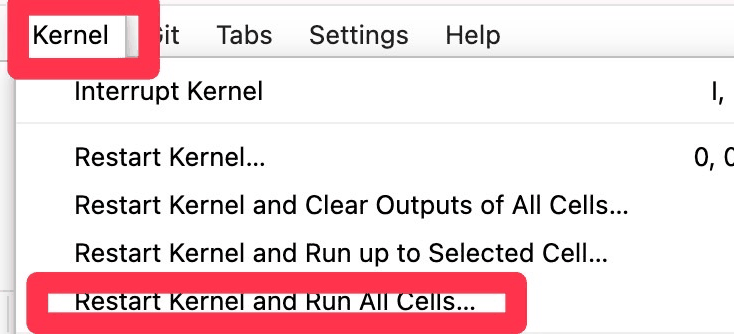

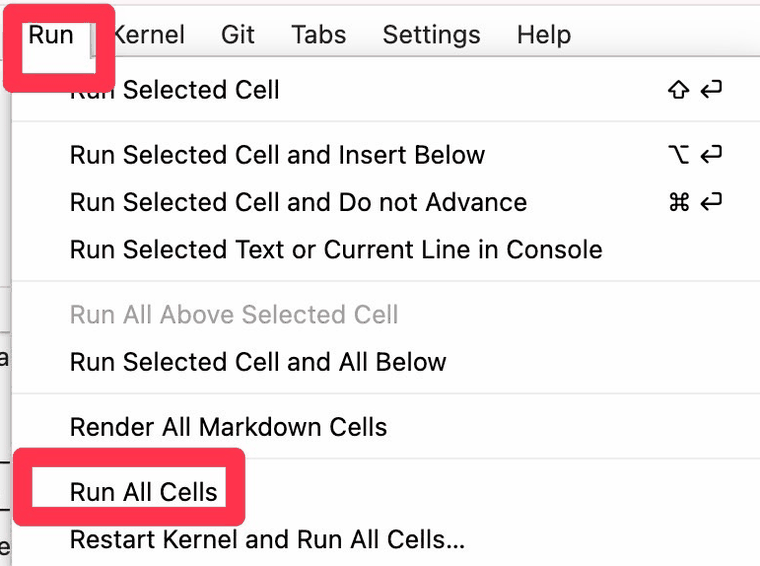

**2️⃣ See a red error message?**

It usually means a step above was skipped, or cells were run out of order. That is not your fault. Run everything again from the top (step 1).

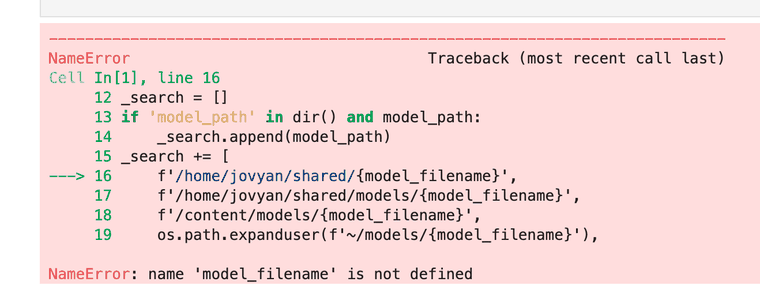

**3️⃣ Did a code cell open up?**

Most code is hidden on purpose. If a cell expanded when you clicked it, you do not need to read or change it. Click the blue bar on its left (JupyterHub) to collapse it, then keep going. Please do not re-run code cells one by one; run everything from the top instead.

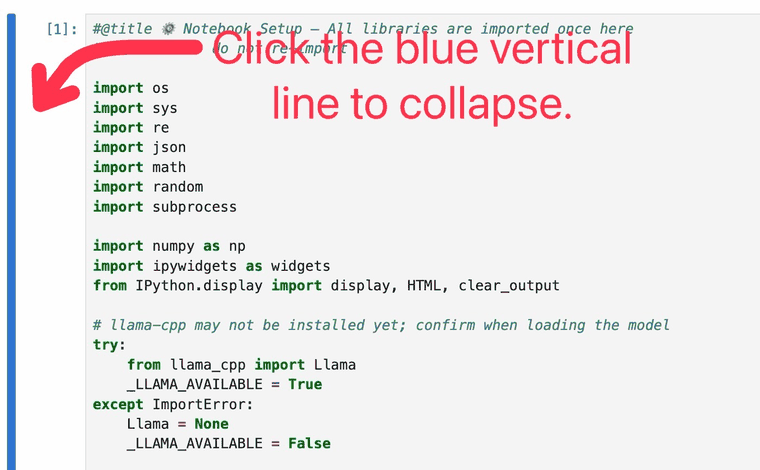

**4️⃣ What does `[*]` mean?**

The cell is still running. Wait until it turns into a number such as `[3]`. Loading the language model can take a minute or two.

![A cell that is still running shows [*]](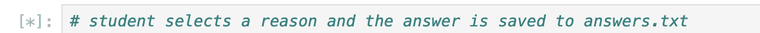)

**5️⃣ Still stuck?**

Refresh the page and run everything again from the top. If it still does not work, tell your instructor which step you are on.

</details>

In [ ]:
#@title 🔬 Helper functions (run once)
import uuid, json, os, time, threading, html as _html
import ipywidgets as widgets
from IPython.display import display, HTML

_FORM_URL = "https://docs.google.com/forms/d/e/1FAIpQLSfj6fQ0qPa9oQ-n8qbtRAb2h8qJzLo0eBPiwz7dveIV0BMAdw/formResponse"
_ENTRY = {"session": "entry.817703458", "notebook": "entry.1518647579", "version": "entry.2104588287", "step": "entry.1456104355", "choice": "entry.1167752725", "reason": "entry.2099469986", "confidence": "entry.1190945772", "extra": "entry.1044793006"}
NOTEBOOK_ID = "NLP_Map_Explorer"
NOTEBOOK_VERSION = "2026-10-v4"
def _get_session():
    """Random code (not linked to your name). Reused for a few hours so a restart keeps the same code."""
    p = os.path.expanduser("~/.notebook_session_" + NOTEBOOK_ID)
    try:
        if os.path.exists(p):
            sid, ts = open(p).read().strip().split("|")
            if time.time() - float(ts) < 6 * 3600:
                return sid
    except Exception:
        pass
    sid = uuid.uuid4().hex[:8]
    try:
        open(p, "w").write(sid + "|" + str(time.time()))
    except Exception:
        pass
    return sid
if "SESSION_ID" not in globals():
    SESSION_ID = _get_session()
SHARE_ANSWERS = True

def _save_local_copy(rec):
    try:
        with open(os.path.expanduser("~/notebook_responses.jsonl"), "a", encoding="utf-8") as f:
            f.write(json.dumps(rec, ensure_ascii=False) + "\n")
    except Exception:
        pass

def _post(rec):
    try:
        import requests
        data = {_ENTRY[k]: str(rec.get(k, "")) for k in _ENTRY}
        for _ in range(2):
            try:
                if requests.post(_FORM_URL, data=data, timeout=10).ok:
                    return True
            except Exception:
                pass
    except Exception:
        pass
    return False

def log_event(step, choice="", reason="", confidence="", extra="", wait=False):
    """Returns True (sent), False (could not send) or None (sharing is off)."""
    rec = {"session": SESSION_ID, "notebook": NOTEBOOK_ID, "version": NOTEBOOK_VERSION, "step": step,
           "choice": choice, "reason": reason, "confidence": confidence, "extra": extra}
    _save_local_copy(rec)
    if not SHARE_ANSWERS:
        return None
    if wait:
        return _post(rec)
    threading.Thread(target=_post, args=(rec,), daemon=True).start()
    return True

_CONF = ["— choose —", "1 (not sure at all)", "2", "3", "4", "5 (very sure)"]
def _val(v):
    return "" if str(v).startswith("—") else str(v)
def _esc(s):
    return _html.escape(str(s)).replace("\n", "<br>")
def _box(inner, color="#166534", bg="#f0fdf4"):
    return HTML(f'<div style="border-left:4px solid {color};background:{bg};padding:10px 14px;'
                f'border-radius:6px;max-width:640px;font-family:sans-serif;font-size:14px;color:#111">{inner}</div>')
def _note(ok):
    if ok is None:
        return "Your answer stays in this notebook only (you chose not to send answers)."
    return "Sent anonymously. A copy also stays in this notebook." if ok else \
           "Could not send right now, but your answer is kept here in this notebook."

def choose_and_justify(step, options, reason_label="Why? Explain your thinking.", extra=""):
    choice_w = widgets.Dropdown(options=["— choose —"] + list(options), description="Your choice:",
                                style={"description_width": "95px"}, layout=widgets.Layout(width="560px"))
    reason_w = widgets.Textarea(placeholder=reason_label, layout=widgets.Layout(width="640px", height="120px"))
    conf_w = widgets.Dropdown(options=_CONF, description="How sure are you?",
                              style={"description_width": "140px"}, layout=widgets.Layout(width="360px"))
    btn = widgets.Button(description="Submit my answer", button_style="primary")
    status = widgets.HTML("")
    display(widgets.VBox([choice_w, reason_w, conf_w, widgets.HBox([btn, status])]))
    receipt = display(HTML(""), display_id=True)
    def _on(_):
        c, r, k = _val(choice_w.value), reason_w.value.strip(), _val(conf_w.value)
        if not (c and r and k):
            status.value = '<span style="color:#b45309">&nbsp;Please choose an option, write a short reason, and say how sure you are.</span>'
            return
        btn.disabled = True
        status.value = "&nbsp;Saving…"
        ok = log_event(step, choice=c, reason=r, confidence=k[0], extra=extra, wait=True)
        status.value = ""
        receipt.update(_box("<b>Your recorded answer</b><br>"
                            f"<b>Choice:</b> {_esc(c)}<br><b>Reason:</b> {_esc(r)}<br>"
                            f"<b>How sure:</b> {_esc(k)}<br><span style='color:#555;font-size:12px'>{_note(ok)}</span>"))
    btn.on_click(_on)

def quick_predict(step, options, answer=None, extra=""):
    choice_w = widgets.Dropdown(options=["— choose —"] + list(options), description="My prediction:",
                                style={"description_width": "110px"}, layout=widgets.Layout(width="520px"))
    conf_w = widgets.Dropdown(options=_CONF, description="How sure?",
                              style={"description_width": "80px"}, layout=widgets.Layout(width="300px"))
    btn = widgets.Button(description="Lock in my prediction", button_style="primary")
    status = widgets.HTML("")
    display(widgets.VBox([choice_w, conf_w, widgets.HBox([btn, status])]))
    receipt = display(HTML(""), display_id=True)
    def _on(_):
        c, k = _val(choice_w.value), _val(conf_w.value)
        if not c:
            status.value = '<span style="color:#b45309">&nbsp;Pick an option first.</span>'
            return
        btn.disabled = True
        ex = extra
        if answer is not None:
            ex = (extra + ";" if extra else "") + "correct=" + str(c == list(options)[answer])
        ok = log_event(step, choice=c, confidence=k[:1], extra=ex)
        receipt.update(_box(f"<b>Your prediction:</b> {_esc(c)}" + (f" &nbsp;(<b>how sure:</b> {_esc(k)})" if k else "") +
                            "<br><span style='color:#555;font-size:12px'>Now read on and check it. "
                            "Being wrong here is useful, it is how you learn.</span>"))
    btn.on_click(_on)


_RATE = ["— choose —", "1 (not at all)", "2", "3", "4", "5 (very well)"]
_AGREE = ["— choose —", "1 (strongly disagree)", "2", "3", "4", "5 (strongly agree)"]
def check_block(phase, mcq=None, rating=None, scenario=None, helpful=None):
    """phase = 'PRE' (no feedback) or 'POST' (feedback on multiple-choice). mcq may be one dict or a list of dicts."""
    phase = phase.upper()
    W = widgets
    lay = lambda w: W.Layout(width=w)
    mcqs = [] if not mcq else (list(mcq) if isinstance(mcq, (list, tuple)) else [mcq])
    items, n = [], 0
    head = ("🧭 Before you start: a quick check" if phase == "PRE" else "✅ Check what you learned")
    sub = ("<b>It is completely OK if you don't know the answers.</b> This is not a test and nothing is graded. "
           "We just want to see how your thinking changes after you finish the notebook, so please give your honest best guess "
           "(or choose “I don't know yet”). "
           "You will get the correct answers at the end of the notebook. It takes about 2 minutes." if phase == "PRE" else
           "Same kind of questions as at the start. Answering is optional and nothing is graded.")
    items.append(W.HTML(f"<h3 style='margin:4px 0'>{head}</h3><div style='color:#444;max-width:640px'>{sub}</div>"))
    if phase == "PRE":
        items.append(W.HTML(_notice_widget().data))
    g, mq = {}, []
    for m in mcqs:
        n += 1
        q = W.Dropdown(options=["— choose —"] + list(m["options"]), layout=lay("640px"))
        c = W.Dropdown(options=_CONF, description="How sure are you?", style={"description_width": "140px"}, layout=lay("360px"))
        mq.append((m, q, c))
        items += [W.HTML(f"<b>{n}. {m['q']}</b>"), q, c]
    if rating:
        n += 1
        g["rt"] = W.Dropdown(options=_RATE, description="My rating:", style={"description_width": "90px"}, layout=lay("320px"))
        items += [W.HTML(f"<b>{n}. {rating}</b>"), g["rt"]]
    if scenario:
        n += 1
        g["sc"] = W.Dropdown(options=["— choose —"] + list(scenario["options"]), layout=lay("640px"))
        g["sr"] = W.Textarea(placeholder=scenario.get("reason_label", "Why?"), layout=W.Layout(width="640px", height="90px" if phase == "PRE" else "120px"))
        items += [W.HTML(f"<b>{n}. {scenario['prompt']}</b>"), g["sc"], g["sr"]]
    if helpful:
        n += 1
        g["hr"] = W.Dropdown(options=_AGREE, layout=lay("320px"))
        g["ha"] = W.Dropdown(options=["— choose —"] + list(helpful["activities"]), layout=lay("640px"))
        g["hw"] = W.Textarea(placeholder="Why? (optional)", layout=W.Layout(width="640px", height="70px"))
        items += [W.HTML(f"<b>{n}. This notebook helped me understand {helpful['topic']}.</b>"), g["hr"],
                  W.HTML("<b>&nbsp;&nbsp;Which part helped you most?</b>"), g["ha"], g["hw"]]
    btn = W.Button(description="Submit", button_style="primary")
    status = W.HTML("")
    items.append(W.HBox([btn, status]))
    display(W.VBox(items))
    receipt = display(HTML(""), display_id=True)

    def _on(_):
        miss = []
        for i, (m, q, c) in enumerate(mq, 1):
            if not (_val(q.value) and _val(c.value)): miss.append(f"question {i} (choice and how sure)")
        if rating and not _val(g["rt"].value): miss.append("your rating")
        if scenario and not (_val(g["sc"].value) and g["sr"].value.strip()): miss.append("the scenario question (choice and a short reason)")
        if helpful and not (_val(g["hr"].value) and _val(g["ha"].value)): miss.append("the last question (rating and which part helped)")
        if miss:
            status.value = '<span style="color:#b45309">&nbsp;Please complete: ' + ", ".join(miss) + ".</span>"
            return
        btn.disabled = True
        status.value = "&nbsp;Saving…"
        recs, shown, fb = [], [], ""
        for i, (m, q, c) in enumerate(mq, 1):
            cv, k = _val(q.value), _val(c.value)
            ok_ans = (cv == list(m["options"])[m["answer"]])
            recs.append(dict(step=phase + ("-mcq" if i == 1 else f"-mcq{i}"), choice=cv, confidence=k[0], extra=f"correct={ok_ans};topic={m.get('topic','')}"))
            shown.append(f"<b>Question {i}:</b> {_esc(cv)} (how sure: {_esc(k)})")
            if phase == "POST":
                _idk = cv.startswith("I don't know")
                fb += (f"<br>Q{i}: ✅ <b>Correct.</b> " if ok_ans else (f"<br>Q{i}: That's OK. " if _idk else f"<br>Q{i}: ❌ <b>Not quite.</b> ") + "The best answer is: "
                       + _esc(list(m["options"])[m["answer"]]) + ". ") + _esc(m.get("explain", ""))
        if rating:
            r = _val(g["rt"].value)
            recs.append(dict(step=phase + "-rating", choice=r[0], extra=f"topic={mcqs[0].get('topic','') if mcqs else ''}"))
            shown.append(f"<b>Self-rating:</b> {_esc(r)}")
        if scenario:
            cv, t = _val(g["sc"].value), g["sr"].value.strip()
            recs.append(dict(step=scenario["step"], choice=cv, reason=t))
            shown.append(f"<b>Your choice:</b> {_esc(cv)}<br><b>Your reason:</b> {_esc(t)}")
        if helpful:
            hr, ha, hw = _val(g["hr"].value), _val(g["ha"].value), g["hw"].value.strip()
            recs.append(dict(step="POST-helpful", choice=hr[0]))
            recs.append(dict(step="POST-helpful-part", choice=ha, reason=hw))
            shown.append(f"<b>Helpful:</b> {_esc(hr)}<br><b>Most helpful part:</b> {_esc(ha)}" + (f"<br><b>Why:</b> {_esc(hw)}" if hw else ""))
        results = []
        def _one(rec):
            results.append(log_event(wait=True, **rec))
        th = [threading.Thread(target=_one, args=(r,), daemon=True) for r in recs]
        for t_ in th: t_.start()
        for t_ in th: t_.join(timeout=25)
        status.value = ""
        ok = (None if (results and all(x is None for x in results)) else (len(results) == len(recs) and all(results)))
        later = "<br><i>Thanks! You will see the same kind of questions at the end of the notebook, together with the correct answers.</i>" if phase == "PRE" else ""
        receipt.update(_box("<b>Your recorded answers</b><br>" + "<br>".join(shown) + fb + later +
                            f"<br><span style='color:#555;font-size:12px'>{_note(ok)}</span>"))
    btn.on_click(_on)

def one_liner(step, label="What surprised you most, or what is still unclear? (optional)"):
    text_w = widgets.Textarea(placeholder=label, layout=widgets.Layout(width="640px", height="70px"))
    btn = widgets.Button(description="Send (optional)", button_style="")
    display(widgets.VBox([text_w, btn]))
    receipt = display(HTML(""), display_id=True)
    def _on(_):
        t = text_w.value.strip()
        if not t:
            return
        btn.disabled = True
        ok = log_event(step, reason=t, wait=True)
        receipt.update(_box(f"<b>Your note:</b> {_esc(t)}<br><span style='color:#555;font-size:12px'>{_note(ok)}</span>"))
    btn.on_click(_on)

def _notice_widget():
    return (_box("<b>🔒 About the questions and quizzes in this notebook.</b> Your answers are sent anonymously "
                 "(a random code, no name or email) to help improve these notebooks. Nothing is graded, and answering "
                 "the “explain your thinking” questions is optional."
                 "<details style='margin-top:6px'><summary style='cursor:pointer'>More about how answers are recorded</summary>"
                 "<div style='margin-top:6px'>Some activities ask you to choose an answer and explain your thinking. There are no right or wrong "
                 "answers to those questions. The quiz questions also record which option you picked and whether it was correct. "
                 "A copy of what you submit also stays in your notebook.</div></details>",
                 color="#1d4ed8", bg="#eff6ff"))


In [ ]:
#@title 🧭 Before you start
# Safety check: stops with a friendly hint if an earlier step was skipped.
if any(_n not in globals() for _n in ("check_block",)): raise type('RunFromTop', (Exception,), {'_render_traceback_': lambda self: ['⚠️ A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.']})('A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.')
check_block("PRE", mcq=[{'topic': 'next-token', 'q': 'Your phone suggests the next word as you type “See you…”. How does it most likely pick the suggestion?', 'options': ['A. It understands what you feel and what you mean', 'B. It looks the sentence up in a list of finished sentences', 'C. It picks words that most often come next, based on lots of text it learned from', 'D. A person types the suggestion for you', "I don't know yet"], 'answer': 2, 'explain': 'Language models work by predicting likely next words (tokens) from patterns in text they were trained on.'}], rating='How well do you understand how a language model produces text?', scenario={'step': 'PRE-scenario', 'prompt': 'A company wants a bot to answer “What is your return policy?” Which would you build first?', 'options': ['Rules and a fixed FAQ', 'A language model on its own', 'A language model that looks up the policy and cites it', 'Not sure'], 'reason_label': 'In one sentence, why?'})

In [1]:
#@title ⚙️ Notebook Setup — All libraries are imported once here
# Later cells do not re-import

import os
import sys
import re
import json
import math
import random
import subprocess

import numpy as np
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

# llama-cpp may not be installed yet; confirm when loading the model
try:
    from llama_cpp import Llama
    _LLAMA_AVAILABLE = True
except ImportError:
    Llama = None
    _LLAMA_AVAILABLE = False

print('Setup complete.')
print(f'llama-cpp-python available: {_LLAMA_AVAILABLE}')
print('(The model is only loaded in the “Load language model” cell.)')


Setup complete.
llama-cpp-python available: True
(The model is only loaded in the “Load language model” cell.)


## 🗺️ First: Build the Thinking Path

This notebook is not about memorizing jargon. Build this path:

> **Problem / Data → Why a capability is needed → Which method family fits → What its limits are**

> 💬 **Zoey:** “So text means we should always use ChatGPT?”  
> **HAC:** “Not yet. ChatGPT is powerful, but not every text problem needs a large language model. We learn *why*, not slogans.”


## 🧭 Part 1: When Are Traditional Methods Not Enough?


Before modern NLP, test your intuition with realistic scenarios.  
For each question, decide: **Are rules / keywords / simple statistics enough, or do we need stronger NLP or a language model?**


In [2]:
#@title Part 1: Scenario quiz — rules enough, or stronger NLP?
# Safety check: stops with a friendly hint if an earlier step was skipped.
if any(_n not in globals() for _n in ("random", "widgets",)): raise type('RunFromTop', (Exception,), {'_render_traceback_': lambda self: ['⚠️ A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.']})('A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.')
quiz_bank = [
    {
        "question": "You filter spam whose subject always contains “You won a prize.” The rule barely changes. This task:",
        "options": ["A. Keywords / rules are usually enough", "B. A large language model is required"],
        "correct": 0,
        "explanation": "✅ Correct! When the format is fixed and keywords are stable, rules or simple classifiers are often faster, cheaper, and easier to debug."
    },
    {
        "question": "Customer reviews are full of sarcasm, e.g. “Awesome — waited three weeks for a broken package.” You need the real sentiment:",
        "options": ["A. Rules that count positive words are enough", "B. Usually needs stronger semantic understanding (modern NLP / LMs)"],
        "correct": 1,
        "explanation": "✅ Correct! Positive wording with negative meaning is a classic semantic hard case; keywords alone fail often."
    },
    {
        "question": "You translate French product manuals into English, with lots of context and technical terms:",
        "options": ["A. Word-by-word dictionary lookup is enough", "B. Machine translation / modern NLP is more common"],
        "correct": 1,
        "explanation": "✅ Correct! Translation needs context and fluency; modern sequence models beat pure dictionary lookup."
    },
    {
        "question": "An FAQ bot answers only 8 fixed questions (hours, address, returns…). Users mostly click buttons:",
        "options": ["A. A flow-based chatbot / rule flow is often a great fit", "B. Impossible without a GPT-level model"],
        "correct": 0,
        "explanation": "✅ Correct! Small scope and fixed answers favor flowchart + button navigation. Large models can help later, but are not the required starting point."
    },
    {
        "question": "Employees ask in many phrasings whether temporary remote work abroad is allowed. Answers must follow company policy docs:",
        "options": ["A. Let the model answer from memory", "B. Better to retrieve documents (RAG) then answer"],
        "correct": 1,
        "explanation": "✅ Correct! Policies change and answers should be traceable. Retrieve evidence first; don’t rely on memorized model knowledge alone."
    },
    {
        "question": "Extract dates, amounts, and party names from contracts:",
        "options": ["A. Information extraction / NER is a natural direction", "B. Only humans can do this"],
        "correct": 0,
        "explanation": "✅ Correct! This is classic information extraction; rules, traditional ML, or modern NER models can all apply depending on complexity."
    },
]

N_QUIZ = 4
quiz_questions = random.sample(quiz_bank, N_QUIZ)
current_q = 0
score = 0

question_label = widgets.HTML()
options_widget = widgets.RadioButtons(options=[], layout=widgets.Layout(width="720px"))
submit_btn = widgets.Button(description="Submit Answer", button_style="primary", disabled=True)
next_btn = widgets.Button(description="Next →", button_style="info", disabled=True)
feedback_area = widgets.HTML()
progress_label = widgets.HTML()

def on_option_change(change):
    submit_btn.disabled = (change["new"] is None)

options_widget.observe(on_option_change, names="value")

def show_question():
    global current_q
    q = quiz_questions[current_q]
    question_label.value = (
        f"<h3>Question {current_q+1} / {len(quiz_questions)}</h3>"
        f"<p style='color:#64748b; font-size:13px'>(Randomly sampled from a bank of {len(quiz_bank)} questions)</p>"
        f"<p style='font-size:15px'>{q['question']}</p>"
    )
    options_widget.options = q["options"]
    options_widget.value = None
    submit_btn.disabled = True
    feedback_area.value = ""
    next_btn.disabled = True
    progress_label.value = f"<p style='color:#334155; font-weight:600'>Score: {score} / {current_q}</p>"

def on_submit(b):
    global score, current_q
    if options_widget.value is None:
        feedback_area.value = "<p style='color:orange'>Please select an answer first.</p>"
        return
    selected_idx = options_widget.options.index(options_widget.value)
    q = quiz_questions[current_q]
    if 'log_event' in globals():
        log_event(f"A-scenario-q{current_q+1}", choice=str(selected_idx+1), extra=f"correct={selected_idx == q['correct']}")
    if selected_idx == q["correct"]:
        score += 1
        feedback_area.value = (
            f"<div style='color:#14532d; font-weight:bold; margin-top:8px; padding:12px; "
            f"background:#dcfce7; border-radius:8px; border:1px solid #86efac'>{q['explanation']}</div>"
        )
    else:
        feedback_area.value = (
            f"<div style='color:#7f1d1d; font-weight:bold; margin-top:8px; padding:12px; "
            f"background:#fee2e2; border-radius:8px; border:1px solid #fca5a5'>"
            f"❌ Not quite.<br><br>{q['explanation']}</div>"
        )
    submit_btn.disabled = True
    next_btn.disabled = False
    progress_label.value = f"<p style='color:#334155; font-weight:600'>Score: {score} / {current_q+1}</p>"

def on_next(b):
    global current_q
    current_q += 1
    if current_q < len(quiz_questions):
        show_question()
    else:
        question_label.value = f"<h3>🎉 Quiz complete!</h3><p style='font-size:16px'>Final score: <b>{score} / {len(quiz_questions)}</b></p>"
        options_widget.options = []
        feedback_area.value = """
        <div style='background:#1e3a5f; padding:16px; border-radius:10px; margin-top:12px; border-left:6px solid #60a5fa; color:#f1f5f9'>
        <b style='color:#93c5fd; font-size:16px'>Key takeaway:</b><br><br>
        <span style='color:#f8fafc'>Rules fit fixed, low-variation tasks;</span><br>
        <span style='color:#e2e8f0'>semantics, ambiguity, generation, and open dialogue more often need modern NLP / LMs;</span><br>
        <span style='color:#e2e8f0'>when you need up-to-date or internal knowledge, think retrieval and evidence (RAG), not model memory alone.</span>
        </div>
        """
        submit_btn.disabled = True
        next_btn.disabled = True
        progress_label.value = ""

submit_btn.on_click(on_submit)
next_btn.on_click(on_next)
show_question()
display(progress_label, question_label, options_widget, widgets.HBox([submit_btn, next_btn]), feedback_area)


HTML(value="<p style='color:#334155; font-weight:600'>Score: 0 / 0</p>")

HTML(value="<h3>Question 1 / 4</h3><p style='color:#64748b; font-size:13px'>(Randomly sampled from a bank of 6…

RadioButtons(layout=Layout(width='720px'), options=('A. Let the model answer from memory', 'B. Better to retri…

HTML(value='')

> 💬 **Zoey:** “So sometimes rules are enough, and sometimes we really need a smarter model?”  
> **HAC:** “Yes. Look at **how much the problem varies** and **how deep the understanding must be**, then choose the complexity.”


## 🧩 Part 2: What Is NLP Doing?

Natural Language Processing is the field of techniques that let computers process, understand, and generate human language.

A useful teaching split (modern systems often cross both):

| Direction | Full name | Intuition |
|-----------|-----------|-----------|
| **NLU** | Natural Language Understanding | Read: classify, extract, intent, sentiment |
| **NLG** | Natural Language Generation | Write: summarize, translate, reply, create |

> Don’t memorize definitions. Ask: is this task more about understanding, generation, or both?


### 📚 Structured Data vs. Natural Language

Computers traditionally shine on clean structured data — ages, amounts, dates, categories in tables.

But much human information is not a tidy table:
- Email, chat, reviews
- Contracts and policy documents
- Speech transcribed into text

NLP works on language that is **messy, ambiguous, and context-dependent**.


## 🧠 Modern NLP Mental Map


We know NLP covers understanding and generation.  
Before memorizing model names, lock in this modern path:

> **Text → Tokenization → Embedding → Transformer → LLM → Task**  
> If you need external / up-to-date knowledge, add **Retrieval → RAG**


<div style="text-align:center; margin: 12px 0 28px 0;">
  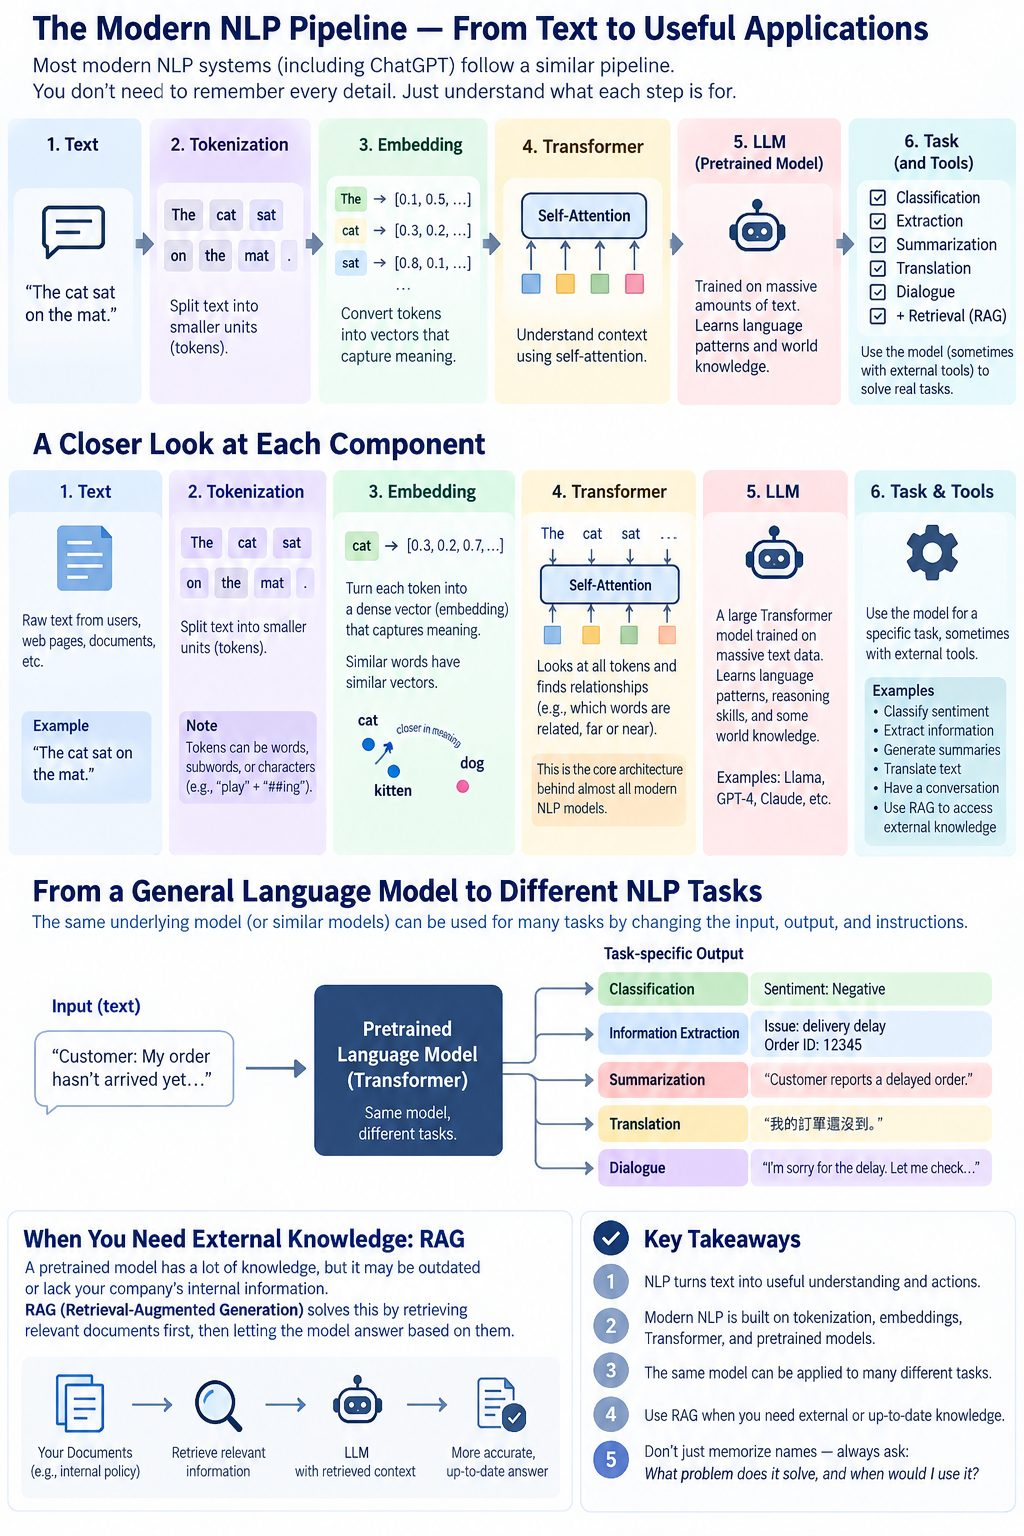
</div>


## 🔬 Part 3: Meet a Real Small Language Model (SLM)

So far we stayed conceptual. Here we load a **Small Language Model** so you can see:

1. How it “guesses the next token” for a sentence  
2. How the same model can do sentiment or NER when you change the prompt  

> This is not about training a model. It is about intuition:  
> **A core behavior of modern LLMs / SLMs is predicting the next token under context.**


In [3]:
#@title Load language model（set up the environment, then load once here only）
# Runs once. On JupyterHub the model is already in the shared folder, so nothing is downloaded.
# On Colab the first run installs a package and downloads the model (about 0.8 GB, a few minutes).
import os, sys, subprocess

def detect_env():
    try:
        import google.colab  # noqa: F401
        return 'colab'
    except ImportError:
        pass
    if os.environ.get('JUPYTERHUB_USER') or os.environ.get('JPY_SESSION_NAME'):
        return 'jupyterhub'
    return 'local'

ENV = detect_env()
print(f'Environment detected: {ENV}')

# 1) llama-cpp-python (runs the model)
try:
    from llama_cpp import Llama
    print('llama-cpp-python is ready.')
except ImportError:
    print('Installing llama-cpp-python (about 1-2 minutes)...')
    _base = [sys.executable, '-m', 'pip', 'install', 'llama-cpp-python', '--quiet']
    _r = subprocess.run(_base + ['--only-binary=:all:', '--extra-index-url',
                                 'https://abetlen.github.io/llama-cpp-python/whl/cpu'],
                        capture_output=True, text=True)
    if _r.returncode != 0:   # fall back to building from source (slower)
        print('Prebuilt version not available, building instead (this can take several minutes)...')
        _r = subprocess.run(_base, capture_output=True, text=True)
    if _r.returncode != 0:
        print(_r.stderr[-1500:])
        raise RuntimeError('Could not install llama-cpp-python. Please tell your instructor.')
    import importlib; importlib.invalidate_caches()
    from llama_cpp import Llama
    print('Installed.')
_LLAMA_AVAILABLE = True

# 2) the model file
model_filename = 'Llama-3.2-1B-Instruct-Q4_K_M.gguf'
_url = ('https://huggingface.co/bartowski/Llama-3.2-1B-Instruct-GGUF'
        '/resolve/main/Llama-3.2-1B-Instruct-Q4_K_M.gguf')
_search = [f'/home/jovyan/shared/{model_filename}', f'/home/jovyan/shared/models/{model_filename}',
           f'/content/models/{model_filename}', os.path.expanduser(f'~/models/{model_filename}'),
           f'./models/{model_filename}', f'./{model_filename}']
model_path = next((p for p in _search if os.path.exists(p)), None)

if model_path:
    print(f'Model found: {model_path}  ({os.path.getsize(model_path)/1024**3:.2f} GB)')
else:
    _dir = '/content/models' if ENV == 'colab' else (os.path.expanduser('~/models') if ENV == 'jupyterhub' else './models')
    os.makedirs(_dir, exist_ok=True)
    _dest = os.path.join(_dir, model_filename)
    print(f'Model not found. Downloading to {_dest} (about 0.8 GB, a few minutes)...')
    _ok = False
    for _cmd in (['wget', '-q', '-O', _dest, _url], ['curl', '-sL', '-o', _dest, _url]):
        try:
            if subprocess.run(_cmd).returncode == 0 and os.path.getsize(_dest) > 100_000_000:
                _ok = True; break
        except FileNotFoundError:
            continue
    if not _ok:
        import urllib.request
        urllib.request.urlretrieve(_url, _dest)
        _ok = os.path.getsize(_dest) > 100_000_000
    if not _ok:
        raise RuntimeError('Download failed. Check your internet connection and run this cell again.')
    model_path = _dest
    print(f'Downloaded: {model_path}  ({os.path.getsize(model_path)/1024**3:.2f} GB)')

MODEL_PATH = model_path

llm = Llama(model_path=MODEL_PATH, n_ctx=1024, verbose=False, logits_all=True)
print('Model loaded. You can start.')


Environment detected: jupyterhub
Model loaded. You can start.


### 🎯 How to play: guess first, then see the model

1. Type the start of a sentence (prefer **English**; Chinese may show odd subword splits — a real limit, not a bug)  
2. **Guess** what the model thinks comes next  
3. Run and compare with the probability distribution  


### 🎰 After next-token probabilities — then what?


A language model produces a **next-token probability distribution** at each step.

That single mechanism supports many tasks once you change the prompt and decoding setup.


In [4]:
#@title 🎰 Guess the Next Token + Language Model Probability Chain
# Safety check: stops with a friendly hint if an earlier step was skipped.
if any(_n not in globals() for _n in ("llm", "math", "random", "widgets",)): raise type('RunFromTop', (Exception,), {'_render_traceback_': lambda self: ['⚠️ A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.']})('A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.')

# ============================================================
# EXAMPLE PROMPTS
# ============================================================

example_sentences = [
    "The capital of France is",
    "Peanut butter and",
    "The student opened the",
    "Artificial intelligence will",
    "I went to the bank to",
]


# ============================================================
# GAME STATE
# ============================================================

lm_state = {
    "text": "The student opened the",
    "step": 0,
    "history": []
}


# ============================================================
# WIDGETS
# ============================================================

sentence_box = widgets.Text(
    value=lm_state["text"],
    description="Prompt:",
    style={"description_width": "85px"},
    layout=widgets.Layout(width="620px")
)

guess_box = widgets.Text(
    placeholder="Your guess for the next token (optional)",
    description="Your guess:",
    style={"description_width": "85px"},
    layout=widgets.Layout(width="500px")
)

reveal_btn = widgets.Button(
    description="🔍 Reveal Next Token",
    button_style="primary",
    layout=widgets.Layout(width="200px")
)

reset_btn = widgets.Button(
    description="↺ Reset",
    layout=widgets.Layout(width="100px")
)

mode_choice = widgets.ToggleButtons(
    options=[
        ("👤 Human", "human"),
        ("🥇 Greedy", "greedy"),
        ("🎲 Sampling", "sampling"),
    ],
    value="human",
    description="Mode:",
    style={"description_width": "55px"},
)

temperature_slider = widgets.FloatSlider(
    value=0.8,
    min=0.2,
    max=1.5,
    step=0.1,
    description="Temperature:",
    style={"description_width": "90px"},
    layout=widgets.Layout(width="380px")
)

generate_steps = widgets.IntSlider(
    value=6,
    min=1,
    max=12,
    step=1,
    description="Steps:",
    style={"description_width": "55px"},
    layout=widgets.Layout(width="300px")
)

auto_generate_btn = widgets.Button(
    description="▶ Auto Generate",
    button_style="success",
    layout=widgets.Layout(width="160px")
)

game_output = widgets.Output()
history_output = widgets.Output()


# ============================================================
# MODEL HELPERS
# ============================================================

def get_top_tokens(prompt, top_k=5, temperature=1.0):
    result = llm.create_completion(
        prompt,
        max_tokens=1,
        logprobs=top_k,
        echo=False,
        temperature=temperature
    )

    top_logprobs = (
        result["choices"][0]
        ["logprobs"]
        ["top_logprobs"][0]
    )

    tokens = [
        (tok, math.exp(lp))
        for tok, lp in top_logprobs.items()
    ]

    tokens.sort(
        key=lambda x: x[1],
        reverse=True
    )

    return tokens


def normalize_probs(tokens):
    total = sum(prob for _, prob in tokens)

    if total == 0:
        return tokens

    return [
        (tok, prob / total)
        for tok, prob in tokens
    ]


def sample_token(tokens):
    tokens = normalize_probs(tokens)

    r = random.random()
    cumulative = 0

    for tok, prob in tokens:
        cumulative += prob

        if r <= cumulative:
            return tok, prob

    return tokens[-1]


def visible_token(tok):
    return (
        tok
        .replace(" ", "␠")
        .replace("\n", "↵")
        .replace("\t", "⇥")
    )


# ============================================================
# RENDER TOKEN DISTRIBUTION
# ============================================================

def render_bars(tokens, user_guess=""):
    max_prob = max(prob for _, prob in tokens)

    rows = ""

    for rank, (tok, prob) in enumerate(tokens, start=1):
        pct = prob * 100
        bar_width = (
            prob / max_prob * 100
            if max_prob > 0
            else 0
        )

        display_tok = visible_token(tok)

        guess_match = (
            user_guess.strip()
            and user_guess.strip().lower()
            == tok.strip().lower()
        )

        border = (
            "2px solid #f59e0b"
            if guess_match
            else "1px solid #334155"
        )

        badge = (
            " ← YOUR GUESS"
            if guess_match
            else ""
        )

        rows += f"""
        <div style="
            margin:6px 0;
            padding:8px 10px;
            border:{border};
            border-radius:8px;
            background:#111827;
        ">
          <div style="display:flex;align-items:center;gap:10px;">

            <div style="
                width:26px;
                color:#94a3b8;
                font-size:13px;
            ">
                #{rank}
            </div>

            <div style="
                min-width:120px;
                font-family:monospace;
                font-size:15px;
                font-weight:700;
                color:#f8fafc;
            ">
                {display_tok}
                <span style="font-size:10px;color:#fbbf24;">
                    {badge}
                </span>
            </div>

            <div style="
                flex:1;
                height:14px;
                background:#1e293b;
                border-radius:7px;
                overflow:hidden;
            ">
              <div style="
                  width:{bar_width:.1f}%;
                  height:100%;
                  background:#38bdf8;
              "></div>
            </div>

            <div style="
                min-width:55px;
                text-align:right;
                font-size:13px;
                color:#cbd5e1;
            ">
                {pct:.1f}%
            </div>

          </div>
        </div>
        """

    return rows


# ============================================================
# HISTORY DISPLAY
# ============================================================

def render_history():
    with history_output:
        clear_output()

        if not lm_state["history"]:
            return

        rows = ""

        for i, item in enumerate(lm_state["history"], start=1):
            token = visible_token(item["token"])
            prob = item["prob"] * 100

            rows += f"""
            <tr>
                <td style="padding:5px 10px;">{i}</td>
                <td style="padding:5px 10px;font-family:monospace;">{token}</td>
                <td style="padding:5px 10px;">{prob:.1f}%</td>
                <td style="padding:5px 10px;">{item['mode']}</td>
            </tr>
            """

        display(
            HTML(f"""
            <div style="
                max-width:640px;
                margin-top:14px;
                padding:12px 14px;
                border:1px solid #cbd5e1;
                border-radius:10px;
                background:#f8fafc;
            ">

                <div style="
                    font-size:15px;
                    font-weight:800;
                    margin-bottom:8px;
                ">
                    🔗 Probability Chain History
                </div>

                <table style="
                    border-collapse:collapse;
                    width:100%;
                    font-size:14px;
                ">
                    <tr style="text-align:left;color:#475569;">
                        <th style="padding:5px 10px;">Step</th>
                        <th style="padding:5px 10px;">Token</th>
                        <th style="padding:5px 10px;">Probability</th>
                        <th style="padding:5px 10px;">Mode</th>
                    </tr>
                    {rows}
                </table>

            </div>
            """)
        )


# ============================================================
# ADD TOKEN
# ============================================================

def append_token(tok, prob, mode):
    lm_state["text"] += tok
    lm_state["step"] += 1

    lm_state["history"].append({
        "token": tok,
        "prob": prob,
        "mode": mode
    })

    sentence_box.value = lm_state["text"]

    render_history()


# ============================================================
# HUMAN REVEAL
# ============================================================

def reveal_next(_):
    with game_output:
        clear_output()

        prompt = sentence_box.value

        if not prompt.strip():
            print("⚠️ Please enter a sentence first.")
            return

        lm_state["text"] = prompt

        tokens = get_top_tokens(
            prompt,
            top_k=5,
            temperature=1.0
        )

        guess = guess_box.value

        display(
            HTML(f"""
            <div style="
                background:#0d1420;
                border:1px solid #38bdf8;
                border-radius:12px;
                padding:16px 18px;
                color:#e2e8f0;
                max-width:640px;
            ">

                <div style="
                    font-size:11px;
                    font-weight:800;
                    color:#38bdf8;
                    margin-bottom:5px;
                ">
                    ROUND {lm_state["step"] + 1} — CURRENT CONTEXT
                </div>

                <div style="
                    font-size:18px;
                    font-family:monospace;
                    margin-bottom:15px;
                ">
                    “{prompt}”
                </div>

                <div style="
                    font-size:11px;
                    font-weight:800;
                    color:#fbbf24;
                    margin-bottom:7px;
                ">
                    MODEL'S TOP-5 NEXT TOKENS
                </div>

                {render_bars(tokens, guess)}

            </div>
            """)
        )

        if guess.strip():
            matched = any(
                guess.strip().lower()
                == tok.strip().lower()
                for tok, _ in tokens
            )

            if matched:
                print("🎯 Your guess is in the Top-5!")
            else:
                print("🤔 Your guess is not in the Top-5.")

        if mode_choice.value != "human":
            display(
                HTML("""
                <div style="
                    margin-top:10px;
                    color:#64748b;
                    font-size:14px;
                ">
                    Not in Human mode. You can also use Auto Generate。
                </div>
                """)
            )
            return

        buttons = []

        for tok, prob in tokens:
            btn = widgets.Button(
                description=f"{visible_token(tok)}  ({prob*100:.1f}%)",
                layout=widgets.Layout(
                    width="145px",
                    height="40px"
                )
            )

            def make_handler(chosen_tok, chosen_prob):
                def handler(_):
                    append_token(
                        chosen_tok,
                        chosen_prob,
                        "Human"
                    )

                    guess_box.value = ""

                    with game_output:
                        clear_output()

                    reveal_next(None)

                return handler

            btn.on_click(
                make_handler(tok, prob)
            )

            buttons.append(btn)

        display(
            HTML("""
            <div style="
                margin-top:12px;
                margin-bottom:5px;
                font-weight:700;
            ">
                👤 Human Mode: pick the next token
            </div>
            """)
        )

        display(
            widgets.HBox(
                buttons,
                layout=widgets.Layout(
                    flex_flow="row wrap"
                )
            )
        )


# ============================================================
# AUTO GENERATION
# ============================================================

def auto_generate(_):
    with game_output:
        clear_output()

        lm_state["text"] = sentence_box.value

        steps = generate_steps.value
        mode = mode_choice.value
        temperature = temperature_slider.value

        if mode == "human":
            display(
                HTML("""
                <div style="
                    padding:10px;
                    color:#92400e;
                    background:#fffbeb;
                    border:1px solid #fde68a;
                    border-radius:8px;
                    max-width:620px;
                ">
                    👤 Human mode: press Reveal, then pick a token yourself.
                </div>
                """)
            )
            return

        chain_rows = ""

        for step in range(steps):
            prompt = lm_state["text"]

            tokens = get_top_tokens(
                prompt,
                top_k=5,
                temperature=temperature
            )

            if mode == "greedy":
                chosen_tok, chosen_prob = tokens[0]
                mode_label = "Greedy"

            else:
                chosen_tok, chosen_prob = sample_token(tokens)
                mode_label = f"Sampling T={temperature:.1f}"

            append_token(
                chosen_tok,
                chosen_prob,
                mode_label
            )

            top3_text = " | ".join(
                f"{visible_token(tok)} {prob*100:.1f}%"
                for tok, prob in tokens[:3]
            )

            chain_rows += f"""
            <div style="
                margin:7px 0;
                padding:10px 12px;
                border:1px solid #334155;
                border-radius:8px;
                background:#111827;
            ">

                <div style="
                    font-size:12px;
                    color:#94a3b8;
                ">
                    STEP {lm_state["step"]}
                </div>

                <div style="
                    margin:4px 0;
                    font-size:16px;
                    color:#f8fafc;
                ">
                    Chosen:
                    <b style="color:#38bdf8;">
                        {visible_token(chosen_tok)}
                    </b>
                    &nbsp;
                    ({chosen_prob*100:.1f}%)
                </div>

                <div style="
                    font-size:12px;
                    color:#cbd5e1;
                ">
                    Top candidates: {top3_text}
                </div>

            </div>
            """

        display(
            HTML(f"""
            <div style="
                max-width:640px;
                background:#0d1420;
                border:1px solid #38bdf8;
                border-radius:12px;
                padding:16px;
                color:#e2e8f0;
            ">

                <div style="
                    font-size:13px;
                    font-weight:800;
                    color:#fbbf24;
                    margin-bottom:8px;
                ">
                    🎰 LANGUAGE MODEL PROBABILITY CHAIN
                </div>

                {chain_rows}

                <hr style="
                    border:none;
                    border-top:1px solid #334155;
                    margin:14px 0;
                ">

                <div style="
                    font-size:13px;
                    color:#94a3b8;
                    margin-bottom:5px;
                ">
                    GENERATED TEXT
                </div>

                <div style="
                    font-family:monospace;
                    font-size:18px;
                    line-height:1.55;
                    color:#f8fafc;
                ">
                    {lm_state["text"]}
                </div>

            </div>
            """)
        )


# ============================================================
# EXAMPLE BUTTONS
# ============================================================

example_buttons = []

for text in example_sentences:
    btn = widgets.Button(
        description=text,
        layout=widgets.Layout(
            width="245px",
            height="38px",
            margin="3px"
        )
    )

    def make_example_handler(example_text):
        def handler(_):
            lm_state["text"] = example_text
            lm_state["step"] = 0
            lm_state["history"] = []

            sentence_box.value = example_text
            guess_box.value = ""

            with game_output:
                clear_output()

            with history_output:
                clear_output()

        return handler

    btn.on_click(
        make_example_handler(text)
    )

    example_buttons.append(btn)


# ============================================================
# RESET
# ============================================================

def reset_game(_):
    default_text = "The student opened the"

    lm_state["text"] = default_text
    lm_state["step"] = 0
    lm_state["history"] = []

    sentence_box.value = default_text
    guess_box.value = ""

    with game_output:
        clear_output()

    with history_output:
        clear_output()


reset_btn.on_click(reset_game)
reveal_btn.on_click(reveal_next)
auto_generate_btn.on_click(auto_generate)


# ============================================================
# SYNC MANUAL TEXT EDITING
# ============================================================

def sync_sentence(change):
    if change["name"] == "value":
        lm_state["text"] = change["new"]


sentence_box.observe(
    sync_sentence,
    names="value"
)


# ============================================================
# DISPLAY
# ============================================================

display(
    HTML("""
    <h3 style="
        font-size:23px;
        color:#1e3a8a;
        margin-bottom:4px;
    ">
        🎰 Language Model Probability Chain
    </h3>

    <p style="
        max-width:650px;
        color:#475569;
        font-size:15px;
        line-height:1.55;
    ">
        At each step, the language model uses
        <b>the full current context</b>
        to recompute the next-token probability distribution。
        <br><br>
        It does not plan the whole sentence first, then emit it once.
        Instead:
        <b>predict → choose → append → predict again</b>。
    </p>
    """)
)

display(
    HTML("<b>🎯 Try an example:</b>")
)

display(
    widgets.VBox([
        widgets.HBox(example_buttons[:2]),
        widgets.HBox(example_buttons[2:4]),
        widgets.HBox(example_buttons[4:])
    ])
)

display(HTML("<div style='height:10px'></div>"))

display(sentence_box)
display(guess_box)

display(
    widgets.HBox([
        reveal_btn,
        reset_btn
    ])
)

display(
    HTML("""
    <hr style="
        max-width:640px;
        margin:18px 0 12px;
    ">

    <div style="
        font-size:16px;
        font-weight:800;
        margin-bottom:8px;
    ">
        🔗 Probability Chain Mode
    </div>
    """)
)

display(mode_choice)

display(
    widgets.HBox([
        temperature_slider,
        generate_steps
    ])
)

display(auto_generate_btn)

display(game_output)
display(history_output)


Text(value='The student opened the', description='Prompt:', layout=Layout(width='620px'), style=TextStyle(desc…

Text(value='', description='Your guess:', layout=Layout(width='500px'), placeholder='Your guess for the next t…

ToggleButtons(description='Mode:', options=(('👤 Human', 'human'), ('🥇 Greedy', 'greedy'), ('🎲 Sampling', 'samp…

Button(button_style='success', description='▶ Auto Generate', layout=Layout(width='160px'), style=ButtonStyle(…

Output()

Output()

### 🔦 Game: Attention Spotlight — Context Detective

One core Transformer idea: **a word’s meaning depends on which other words it relates to in context.**

This game avoids formulas. Practice: to understand the highlighted word, which words would you attend to?


In [5]:
#@title 🔦 Game: Attention Spotlight
# Safety check: stops with a friendly hint if an earlier step was skipped.
if any(_n not in globals() for _n in ("widgets",)): raise type('RunFromTop', (Exception,), {'_render_traceback_': lambda self: ['⚠️ A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.']})('A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.')

attention_rounds = [
    {
        "sentence": "The animal didn't cross the street because it was too tired.",
        "focus": "it",
        "question": "What does “it” most likely refer to?",
        "choices": ["animal", "street", "cross"],
        "answer": "animal",
        "why": "too tired fits the animal better, so context links “it” strongly to the animal.",
        "weights": {"animal": 0.82, "street": 0.12, "cross": 0.06},
    },
    {
        "sentence": "The animal didn't cross the street because it was too wide.",
        "focus": "it",
        "question": "What does “it” most likely refer to this time?",
        "choices": ["animal", "street", "cross"],
        "answer": "street",
        "why": "too wide fits the street better. Changing one context word changes the referent.",
        "weights": {"animal": 0.10, "street": 0.84, "cross": 0.06},
    },
    {
        "sentence": "Alex thanked Jordan because they helped finish the report.",
        "focus": "they",
        "question": "In this sentence alone, who does “they” most likely link to?",
        "choices": ["Alex", "Jordan", "report"],
        "answer": "Jordan",
        "why": " Jordan is the person being thanked; “helped finish the report” is the natural reason.",
        "weights": {"Alex": 0.25, "Jordan": 0.68, "report": 0.07},
    },
    {
        "sentence": "The chef put the cake in the fridge because it needed to stay cold.",
        "focus": "it",
        "question": "What does “it” most likely refer to?",
        "choices": ["chef", "cake", "fridge"],
        "answer": "cake",
        "why": "needed to stay cold is why the cake was put in the fridge.",
        "weights": {"chef": 0.05, "cake": 0.88, "fridge": 0.07},
    },
]

att_i = 0
att_score = 0
att_streak = 0
att_answered = False

att_header = widgets.HTML()
att_question = widgets.HTML()
att_choices = widgets.ToggleButtons(style={"button_width": "120px"})
att_submit = widgets.Button(description="🔦 Lock Answer", button_style="primary")
att_next = widgets.Button(description="➡️ Next Case", disabled=True)
att_feedback = widgets.HTML()


def _attention_bars(weights):
    rows = []
    for word, value in weights.items():
        pct = int(round(value * 100))
        rows.append(f"""
        <div style='display:grid;grid-template-columns:85px 1fr 48px;gap:8px;align-items:center;margin:7px 0;'>
          <div style='font-weight:700;'>{word}</div>
          <div style='height:16px;background:#e5e7eb;border-radius:999px;overflow:hidden;'>
            <div style='width:{pct}%;height:100%;background:#6366f1;border-radius:999px;'></div>
          </div>
          <div style='font-size:13px;color:#475569;'>{pct}%</div>
        </div>
        """)
    return "".join(rows)


def show_attention_round():
    global att_answered
    att_answered = False
    q = attention_rounds[att_i]

    att_header.value = f"""
    <div style='font-size:15px;font-weight:700;margin:4px 0 10px 0;'>
      🧠 Score: {att_score} &nbsp;&nbsp; 🔥 Streak: {att_streak} &nbsp;&nbsp; Case {att_i+1}/{len(attention_rounds)}
    </div>
    """

    highlighted = q["sentence"].replace(
        q["focus"],
        f"<span style='background:#fef3c7;padding:2px 6px;border-radius:6px;font-weight:800;'>{q['focus']}</span>",
        1
    )

    att_question.value = f"""
    <div style='max-width:620px;padding:16px 18px;border:2px solid #c7d2fe;border-radius:14px;background:#ffffff;'>
      <div style='font-size:13px;font-weight:800;color:#6366f1;margin-bottom:6px;'>CONTEXT CASE #{att_i+1}</div>
      <div style='font-size:21px;line-height:1.5;font-weight:700;color:#1f2937;'>{highlighted}</div>
      <div style='font-size:16px;margin-top:12px;color:#374151;'>🎯 {q['question']}</div>
    </div>
    """

    att_choices.options = q["choices"]
    att_choices.value = q["choices"][0]
    att_feedback.value = ""
    att_submit.disabled = False
    att_next.disabled = True


def check_attention(_):
    global att_score, att_streak, att_answered
    if att_answered:
        return
    att_answered = True
    q = attention_rounds[att_i]
    selected = att_choices.value
    correct = selected == q["answer"]
    if 'log_event' in globals():
        log_event(f"A-attention-r{att_i+1}", choice=str(selected)[:60], extra=f"correct={correct}")

    if correct:
        att_score += 1
        att_streak += 1
        title = "✅ Nice! Context locked."
        bg = "#ecfdf5"
        border = "#86efac"
    else:
        att_streak = 0
        title = f"🧐 Better answer: {q['answer']}"
        bg = "#fff7ed"
        border = "#fdba74"

    att_feedback.value = f"""
    <div style='max-width:620px;margin-top:12px;padding:14px 16px;border:2px solid {border};border-radius:12px;background:{bg};'>
      <div style='font-size:19px;font-weight:800;margin-bottom:6px;'>{title}</div>
      <div style='font-size:15px;line-height:1.5;margin-bottom:12px;'>{q['why']}</div>
      <div style='font-size:14px;font-weight:800;color:#4338ca;margin-bottom:4px;'>TOY ATTENTION SPOTLIGHT</div>
      {_attention_bars(q['weights'])}
      <div style='font-size:12px;color:#64748b;margin-top:9px;'>⚠️ This is a teaching visualization, not real attention weights from a model.</div>
    </div>
    """

    att_header.value = f"""
    <div style='font-size:15px;font-weight:700;margin:4px 0 10px 0;'>
      🧠 Score: {att_score} &nbsp;&nbsp; 🔥 Streak: {att_streak} &nbsp;&nbsp; Case {att_i+1}/{len(attention_rounds)}
    </div>
    """
    att_submit.disabled = True
    att_next.disabled = False


def next_attention(_):
    global att_i
    att_i = (att_i + 1) % len(attention_rounds)
    show_attention_round()

att_submit.on_click(check_attention)
att_next.on_click(next_attention)

display(HTML("""
<h3 style='font-size:22px;color:#1e3a8a;margin-bottom:4px;'>🔦 Attention Spotlight</h3>
<p style='max-width:620px;font-size:15px;color:#475569;'>The same pronoun can shift its main links when context changes.</p>
"""))
display(att_header, att_question, att_choices, widgets.HBox([att_submit, att_next]), att_feedback)
show_attention_round()


HTML(value='')

HTML(value='')

ToggleButtons(options=(), style=ToggleButtonsStyle(button_width='120px'), value=None)

HTML(value='')

### 📚 Game: RAG Treasure Hunt — Find evidence before answering

Don’t let the model guess blindly. You play the **Retriever**:

1. Read the question  
2. Pick the document most worth searching  
3. Lock the supporting evidence  
4. Only then form the answer  

Teaching version of RAG: **Retrieval → Augmented → Generation**.


In [6]:
#@title 📚 RAG Treasure Hunt
# Safety check: stops with a friendly hint if an earlier step was skipped.
if any(_n not in globals() for _n in ("widgets",)): raise type('RunFromTop', (Exception,), {'_render_traceback_': lambda self: ['⚠️ A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.']})('A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.')
# Staged UI so document choice and evidence do not overlap

rag_cases = [
    {
        "question": "How many paid vacation days do employees get per year?",
        "doc": "🏖️ Vacation Policy",
        "docs": [
            "🏖️ Vacation Policy",
            "💳 Expense Policy",
            "🔐 Security Policy",
            "🏠 Remote Work",
            "🩺 Benefits",
            "🚗 Parking Rules",
        ],
        "snippets": [
            "Full-time employees receive 15 paid vacation days per calendar year.",
            "Vacation requests should normally be submitted at least 5 business days in advance.",
            "Unused vacation may be subject to carry-over limits.",
        ],
        "evidence": "Full-time employees receive 15 paid vacation days per calendar year.",
        "answer": "Full-time employees receive 15 paid vacation days per calendar year.",
    },
    {
        "question": "What is the dinner reimbursement cap?",
        "doc": "💳 Expense Policy",
        "docs": [
            "🏖️ Vacation Policy",
            "💳 Expense Policy",
            "🔐 Security Policy",
            "🏠 Remote Work",
            "🩺 Benefits",
            "🚗 Parking Rules",
        ],
        "snippets": [
            "Business meals require an itemized receipt.",
            "Dinner reimbursement is capped at $45 per person unless pre-approved.",
            "Alcohol is not reimbursable under the standard meal policy.",
        ],
        "evidence": "Dinner reimbursement is capped at $45 per person unless pre-approved.",
        "answer": "Dinner reimbursement is capped at $45 per person unless pre-approved.",
    },
    {
        "question": "Can employees do temporary remote work from abroad?",
        "doc": "🏠 Remote Work",
        "docs": [
            "🏖️ Vacation Policy",
            "💳 Expense Policy",
            "🔐 Security Policy",
            "🏠 Remote Work",
            "🩺 Benefits",
            "🚗 Parking Rules",
        ],
        "snippets": [
            "Temporary remote work outside the employee's home country requires manager and HR approval.",
            "Employees are responsible for maintaining a reliable internet connection.",
            "Remote work arrangements may be reviewed when business needs change.",
        ],
        "evidence": "Temporary remote work outside the employee's home country requires manager and HR approval.",
        "answer": "Yes, but temporary work outside the home country requires manager and HR approval.",
    },
]

rag_i = 0
rag_score = 0

rag_header = widgets.HTML()
rag_question_box = widgets.HTML()
rag_feedback = widgets.HTML()

# Step 1 UI
rag_doc_choice = widgets.ToggleButtons(
    options=[],
    style={"button_width": "150px"},
    layout=widgets.Layout(width="100%", margin="4px 0")
)
rag_doc_button = widgets.Button(
    description="🔍 Search Document",
    button_style="primary",
    layout=widgets.Layout(width="180px")
)
rag_step1 = widgets.VBox([
    widgets.HTML("<div style='font-size:13px;font-weight:700;color:#92400e;margin:8px 0 4px;'>Step 1 · Choose a document</div>"),
    rag_doc_choice,
    rag_doc_button,
])

# Step 2 UI (hidden until document is correct)
rag_evidence_choice = widgets.RadioButtons(
    options=[],
    layout=widgets.Layout(width="100%")
)
rag_evidence_button = widgets.Button(
    description="🧾 Lock Evidence",
    button_style="success",
    layout=widgets.Layout(width="160px")
)
rag_next_button = widgets.Button(
    description="➡️ Next Hunt",
    button_style="info",
    layout=widgets.Layout(width="140px"),
    disabled=True
)
rag_step2 = widgets.VBox([
    widgets.HTML("<div style='font-size:13px;font-weight:700;color:#065f46;margin:12px 0 4px;'>Step 2 · Pick evidence</div>"),
    rag_evidence_choice,
    widgets.HBox([rag_evidence_button, rag_next_button], layout=widgets.Layout(margin="6px 0")),
])
rag_step2.layout.display = "none"

def update_rag_header():
    rag_header.value = f"""
    <div style='max-width:680px;display:flex;justify-content:space-between;align-items:center;
                margin:4px 0 12px;font-family:Arial,sans-serif;'>
      <div style='font-size:20px;font-weight:800;color:#92400e;'>📚 RAG Treasure Hunt</div>
      <div style='font-size:14px;font-weight:700;color:#475569;'>
        💰 Score: {rag_score} &nbsp;·&nbsp; Hunt {rag_i+1}/{len(rag_cases)}
      </div>
    </div>
    <p style='max-width:680px;font-size:14px;color:#475569;margin:0 0 8px;'>
      You are not the LLM. Act as Retriever: find the right document, then the supporting evidence.
    </p>
    """

def show_rag_case():
    global rag_i
    c = rag_cases[rag_i]
    update_rag_header()
    rag_question_box.value = f"""
    <div style='max-width:680px;padding:14px 16px;border:2px solid #fde68a;border-radius:14px;background:#fffbeb;margin-bottom:8px;'>
      <div style='font-size:12px;font-weight:800;color:#92400e;margin-bottom:4px;'>TREASURE HUNT #{rag_i+1}</div>
      <div style='font-size:18px;font-weight:800;color:#1f2937;'>💬 {c['question']}</div>
      <div style='font-size:13px;color:#6b7280;margin-top:6px;'>First pick the best document, then the evidence.</div>
    </div>
    """
    rag_doc_choice.options = list(c["docs"])
    rag_doc_choice.value = c["docs"][0]
    rag_evidence_choice.options = []
    rag_feedback.value = ""
    rag_doc_button.disabled = False
    rag_evidence_button.disabled = True
    rag_next_button.disabled = True
    rag_step1.layout.display = "block"
    rag_step2.layout.display = "none"

def search_rag_doc(_):
    c = rag_cases[rag_i]
    selected = rag_doc_choice.value
    if selected != c["doc"]:
        rag_feedback.value = """
        <div style='max-width:680px;margin-top:10px;padding:12px 14px;background:#fff7ed;
                    border:2px solid #fdba74;border-radius:12px;'>
          🕳️ <b>No useful treasure in this document.</b><br>
          Hint: which policy family matches the key idea in the question?
        </div>
        """
        rag_step2.layout.display = "none"
        return

    rag_evidence_choice.options = list(c["snippets"])
    rag_evidence_choice.value = c["snippets"][0]
    rag_doc_button.disabled = True
    rag_evidence_button.disabled = False
    rag_next_button.disabled = True
    rag_step2.layout.display = "block"
    rag_feedback.value = """
    <div style='max-width:680px;margin-top:10px;padding:12px 14px;background:#ecfdf5;
                border:2px solid #86efac;border-radius:12px;'>
      📂 <b>Document found!</b> Don’t answer yet.<br>
      From the three passages, pick the evidence that directly supports the answer.
    </div>
    """

def lock_rag_evidence(_):
    global rag_score
    c = rag_cases[rag_i]
    selected = rag_evidence_choice.value
    if 'log_event' in globals():
        log_event(f"A-rag-r{rag_i+1}", choice=str(selected)[:60], extra=f"correct={selected == c['evidence']}")
    if selected == c["evidence"]:
        rag_score += 1
        title = "🏆 TREASURE FOUND!"
        bg, border = "#ecfdf5", "#86efac"
        note = "You found the right evidence. Now an LLM would have grounded context to generate an answer."
    else:
        title = "🧭 Close, but not enough evidence."
        bg, border = "#fff7ed", "#fdba74"
        note = "Related topic, but not direct support. RAG must find the right passage, not only the right file."

    update_rag_header()
    rag_feedback.value = f"""
    <div style='max-width:680px;margin-top:12px;padding:14px 16px;background:{bg};
                border:2px solid {border};border-radius:12px;'>
      <div style='font-size:18px;font-weight:800;margin-bottom:6px;'>{title}</div>
      <div style='font-size:14px;line-height:1.5;'>{note}</div>
      <hr style='border:none;border-top:1px solid #d1d5db;margin:10px 0;'>
      <div style='font-size:12px;font-weight:800;color:#475569;'>RAG PIPELINE</div>
      <div style='font-size:15px;font-weight:700;margin:6px 0;'>💬 Question → 🔍 Retrieve → 📄 Evidence → 🤖 Generate</div>
      <div style='font-size:14px;margin-top:6px;'><b>Grounded answer:</b> {c['answer']}</div>
    </div>
    """
    rag_evidence_button.disabled = True
    rag_next_button.disabled = False

def next_rag(_):
    global rag_i
    rag_i = (rag_i + 1) % len(rag_cases)
    show_rag_case()

rag_doc_button.on_click(search_rag_doc)
rag_evidence_button.on_click(lock_rag_evidence)
rag_next_button.on_click(next_rag)

rag_ui = widgets.VBox([
    rag_header,
    rag_question_box,
    rag_step1,
    rag_step2,
    rag_feedback,
], layout=widgets.Layout(max_width="720px"))

display(rag_ui)
show_rag_case()


## 🗺️ Part 4: NLP Task Decision Map

Don’t ask “which model is strongest?” Ask:

1. **What is the data?** (tables? free text? dialogue?)  
2. **What is the goal?** (classify, extract, generate, converse?)  
3. **What are the constraints?** (hallucinations OK? need provenance? compute budget?)


In [7]:
#@title 🧭 Interactive decision map (pick a task type)
# Safety check: stops with a friendly hint if an earlier step was skipped.
if any(_n not in globals() for _n in ("widgets",)): raise type('RunFromTop', (Exception,), {'_render_traceback_': lambda self: ['⚠️ A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.']})('A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.')

decision_map = {
    "Text classification (sentiment, spam, topic)": {
        "Suggested direction": "Traditional ML (e.g., Naive Bayes, Logistic Regression) or a small fine-tuned language model",
        "When to upgrade": "Large data, complex labels, or deeper semantics → consider Transformer models",
        "Modern tools": "scikit-learn, Hugging Face, or an LLM for zero-shot classification",
        "Watch-outs": "Start with a simple baseline before jumping to a heavier model.",
    },
    "Information extraction (names, dates, order IDs)": {
        "Suggested direction": "Fixed format → rules / regex; variable format → NER models",
        "When to upgrade": "When context understanding or highly variable phrasing is required",
        "Modern tools": "spaCy, Hugging Face NER models, or LLM + structured output",
        "Watch-outs": "If rules solve it, prefer rules — fast and maintainable.",
    },
    "Machine translation or summarization": {
        "Suggested direction": "Modern mainstream uses Transformer-based generative models",
        "When to upgrade": "These tasks need generation capacity; classic methods are limited",
        "Modern tools": "Translation/summarization APIs, Hugging Face pipelines, GPT-class models",
        "Watch-outs": "Summarization and translation are NLG; generation quality matters.",
    },
    "Task-oriented chatbot (FAQ, support)": {
        "Suggested direction": "Clear flows → visual flow tools; flexible understanding → LLM + knowledge (RAG)",
        "When to upgrade": "When user phrasing varies a lot, or internal documents must be integrated",
        "Modern tools": "Flow builders, Custom GPT-style tools, RAG frameworks",
        "Watch-outs": "Design the dialogue process first; tools change, process thinking lasts.",
    },
    "Open-ended dialogue / content generation": {
        "Suggested direction": "LLM / SLM with clear prompts and constraints",
        "When to upgrade": "Need stronger style control, tools, or grounded knowledge",
        "Modern tools": "Chat APIs, local SLMs, agent-style tool use when needed",
        "Watch-outs": "Hallucinations, safety, and evaluation still matter.",
    },
}

task_picker = widgets.Dropdown(
    options=list(decision_map.keys()),
    description="Task:",
    layout=widgets.Layout(width="520px"),
    style={"description_width": "60px"},
)
map_out = widgets.HTML()

def render_map(change=None):
    k = task_picker.value
    info = decision_map[k]
    map_out.value = f"""
    <div style='max-width:680px;padding:16px 18px;border:1px solid #93c5fd;border-radius:12px;background:#f8fbff;color:#0f172a;'>
      <div style='font-size:16px;font-weight:800;margin-bottom:10px;'>{k}</div>
      <div style='margin:6px 0;'><b>Suggested direction:</b> {info['Suggested direction']}</div>
      <div style='margin:6px 0;'><b>When to upgrade:</b> {info['When to upgrade']}</div>
      <div style='margin:6px 0;'><b>Modern tools:</b> {info['Modern tools']}</div>
      <div style='margin:6px 0;'><b>Watch-outs:</b> {info['Watch-outs']}</div>
    </div>
    """

task_picker.observe(render_map, names="value")
render_map()
display(task_picker, map_out)


Dropdown(description='Task:', layout=Layout(width='520px'), options=('Text classification (sentiment, spam, to…

HTML(value="\n    <div style='max-width:680px;padding:16px 18px;border:1px solid #93c5fd;border-radius:12px;ba…

### A modern view of tools

| Tool type | Examples | Good for | Note |
|-----------|----------|----------|------|
| Flow / FAQ builders | Chatfuel-style tools | Practicing dialogue structure | UIs change; design logic lasts |
| Knowledge-grounded assistants | Custom GPT-style tools | Quick doc Q&A | Still need scope and verification |
| Small / large language models | SLM / LLM | Generate, classify, extract, rewrite | Same model, different prompts |

> **Tools change; the logic stays:** understand the need → design the process → attach models and knowledge when required.


## 🎯 Part 5: Open Case Study


### Mini-Challenge
You are designing an internal **employee policy Q&A assistant** for a mid-size company:

- Employees ask about leave, expenses, remote work in many phrasings  
- Formal policy documents exist and change over time  
- Answers should preferably cite which rule they come from  
- Budget is limited; you should not jump to the most expensive option first  

**Answer briefly:**
1. Is this mostly NLU, NLG, or both?  
2. Do you want RAG? Why?  
3. Which parts can use rules / flows, and which need a language model?  
4. How would you reduce “confidently wrong policy answers”?


In [8]:
#@title 💡 Sample reasoning (click to reveal)
# Safety check: stops with a friendly hint if an earlier step was skipped.
if any(_n not in globals() for _n in ("widgets",)): raise type('RunFromTop', (Exception,), {'_render_traceback_': lambda self: ['⚠️ A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.']})('A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.')

toggle = widgets.ToggleButton(
    value=False,
    description="Show sample reasoning",
    button_style="info",
    layout=widgets.Layout(width="220px"),
)
case_out = widgets.HTML()

def on_toggle(change):
    if change["new"]:
        case_out.value = """
        <div style='max-width:680px;padding:14px 16px;border:1px solid #93c5fd;border-radius:12px;background:#f8fbff;color:#0f172a;'>
          <p><b>One possible line of thought (not a single correct answer):</b></p>
          <ul>
            <li>This needs both <b>NLU</b> (understand varied questions) and <b>NLG</b> (produce readable answers).</li>
            <li>Because answers must follow formal policy documents that change, <b>RAG</b> is a strong fit.</li>
            <li>Fixed FAQ items (office hours, standard leave form links) can still use simple flows / canned replies.</li>
            <li>To reduce confident wrong answers: retrieve passages, require citations, and route uncertain cases to HR.</li>
            <li>Practical constraints: privacy, cost, and who maintains the knowledge base.</li>
          </ul>
        </div>
        """
    else:
        case_out.value = ""

toggle.observe(on_toggle, names="value")
display(toggle, case_out)


ToggleButton(value=False, button_style='info', description='Show sample reasoning', layout=Layout(width='220px…

HTML(value='')

## 🎤 Project Presentation & Assessment

If you present an NLP mini-project in class, aim for **5–10 minutes**.

### Suggested structure
1. What is the problem, and who is the user?  
2. What process did you design?  
3. Which methods / tools, and why?  
4. Limits and next steps  

Grading can emphasize correctness, depth, and clarity.


## 🧰 Part 6: One Model, Two Tasks

The same small model is not limited to next-token guessing.  
**Change the prompt, and it can run different NLP tasks** — a key property of modern LLMs / SLMs.

Below, the same model does:
- Sentiment analysis  
- Named entity recognition (NER)


In [9]:
#@title 🧰 One model, two tasks: Sentiment / NER
# Safety check: stops with a friendly hint if an earlier step was skipped.
if any(_n not in globals() for _n in ("json", "llm", "re", "widgets",)): raise type('RunFromTop', (Exception,), {'_render_traceback_': lambda self: ['⚠️ A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.']})('A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.')

task_selector = widgets.ToggleButtons(
    options=["Sentiment analysis", "Named entity recognition (NER)"],
    description="Task:",
    style={"description_width": "80px"},
    layout=widgets.Layout(width="100%")
)
input_box = widgets.Textarea(
    value="This product is so “great” — it broke after one use.",
    description="Sentence:",
    style={"description_width": "80px"},
    layout=widgets.Layout(width="560px", height="70px")
)
run_btn = widgets.Button(description="🚀 Run task", button_style="primary",
                         layout=widgets.Layout(width="140px"))
task_status = widgets.HTML(value="")
task_output = widgets.Output()

def extract_json(text):
    match = re.search(r'(\{.*\}|\[.*\])', text, re.DOTALL)
    if not match:
        return None
    try:
        return json.loads(match.group(1))
    except json.JSONDecodeError:
        return None

def run_sentiment(text):
    prompt = f"""Classify the sentiment of the following sentence. Reply ONLY with JSON in this exact format, no other text:
{{"label": "positive" or "negative" or "neutral", "reason": "one short sentence explaining why"}}

Sentence: {text}"""
    response = llm.create_chat_completion(
        messages=[{"role": "user", "content": prompt}], max_tokens=150, temperature=0.2
    )
    reply = response["choices"][0]["message"]["content"]
    return extract_json(reply), reply

def run_ner(text):
    prompt = f"""Extract named entities from the following sentence. Reply ONLY with a JSON list, no other text, in this exact format:
[{{"text": "entity text", "type": "PERSON" or "LOCATION" or "ORGANIZATION"}}]
If there are no entities, reply with an empty list: []

Sentence: {text}"""
    response = llm.create_chat_completion(
        messages=[{"role": "user", "content": prompt}], max_tokens=200, temperature=0.2
    )
    reply = response["choices"][0]["message"]["content"]
    return extract_json(reply), reply

def highlight_entities(text, entities):
    colors = {"PERSON": "#38bdf8", "LOCATION": "#a6e3a1", "ORGANIZATION": "#f9e2af"}
    highlighted = text
    for ent in entities:
        ent_text = ent.get("text", "")
        ent_type = ent.get("type", "OTHER")
        color = colors.get(ent_type, "#c9c9c9")
        if ent_text and ent_text in highlighted:
            highlighted = highlighted.replace(
                ent_text,
                f'<span style="background:{color}33;border-bottom:2px solid {color};'
                f'padding:1px 3px;border-radius:3px">{ent_text} '
                f'<span style="font-size:0.7em;color:{color}">{ent_type}</span></span>'
            )
    return highlighted

def on_run(b):
    with task_output:
        clear_output()
        text = input_box.value.strip()
        if not text:
            display(HTML('<span style="color:#f87171">Please enter a sentence first.</span>'))
            return
        if "llm" not in globals() or llm is None:
            display(HTML(
                '<div style="color:#f87171;padding:12px;background:#451a1a;border-radius:8px;">'
                '❌ Model not loaded.<br>'
                'Run the “Load language model” cell first, then try again.'
                '</div>'
            ))
            return

        task_status.value = '<p style="color:#38bdf8;font-weight:700;">⏳ Running… please wait.</p>'
        run_btn.disabled = True
        try:
            if "Sentiment" in task_selector.value:
                parsed, raw_reply = run_sentiment(text)
                if parsed and "label" in parsed:
                    label_colors = {"positive": "#a6e3a1", "negative": "#f87171", "neutral": "#f9e2af"}
                    color = label_colors.get(parsed["label"], "#c9c9c9")
                    html = f"""
                    <div style="font-family:monospace;background:#0d1420;border:1px solid #38bdf8;
                                border-radius:12px;padding:16px 20px;color:#e2e8f0;width:600px">
                      <div style="font-size:0.7em;color:#38bdf8;text-transform:uppercase;margin-bottom:8px">Sentiment result</div>
                      <div style="margin-bottom:10px">"{text}"</div>
                      <div style="display:inline-block;padding:4px 12px;border-radius:20px;
                                  background:{color}33;color:{color};font-weight:bold">
                        {parsed["label"].upper()}
                      </div>
                      <div style="margin-top:10px;color:#a6adc8;font-size:0.9em">{parsed.get("reason","")}</div>
                    </div>"""
                    display(HTML(html))
                else:
                    display(HTML(f'<div style="color:#f9e2af">Model did not return clean JSON. Raw reply:<br><pre style="white-space:pre-wrap">{raw_reply}</pre></div>'))
                    display(HTML('<div style="color:#a6adc8;font-size:0.85em">Note: small models sometimes ignore format instructions — a real-world limitation.</div>'))
            else:
                parsed, raw_reply = run_ner(text)
                if parsed is not None:
                    if len(parsed) == 0:
                        html = f"""
                        <div style="font-family:monospace;background:#0d1420;border:1px solid #38bdf8;
                                    border-radius:12px;padding:16px 20px;color:#e2e8f0;width:600px">
                          <div style="font-size:0.7em;color:#38bdf8;text-transform:uppercase;margin-bottom:8px">NER result</div>
                          <div>"{text}"</div>
                          <div style="margin-top:10px;color:#a6adc8">No person/location/organization entities found.</div>
                        </div>"""
                    else:
                        highlighted = highlight_entities(text, parsed)
                        html = f"""
                        <div style="font-family:monospace;background:#0d1420;border:1px solid #38bdf8;
                                    border-radius:12px;padding:16px 20px;color:#e2e8f0;width:600px">
                          <div style="font-size:0.7em;color:#38bdf8;text-transform:uppercase;margin-bottom:8px">NER result</div>
                          <div style="line-height:2">{highlighted}</div>
                        </div>"""
                    display(HTML(html))
                else:
                    display(HTML(f'<div style="color:#f9e2af">Model did not return clean JSON. Raw reply:<br><pre style="white-space:pre-wrap">{raw_reply}</pre></div>'))
                    display(HTML('<div style="color:#a6adc8;font-size:0.85em">Note: small models sometimes ignore format instructions — a real-world limitation.</div>'))
        except Exception as e:
            display(HTML(
                f'<div style="color:#f87171;padding:12px;background:#451a1a;border-radius:8px;">'
                f'❌ Error while running:<br><pre style="white-space:pre-wrap">{type(e).__name__}: {e}</pre></div>'
            ))
        finally:
            run_btn.disabled = False
            task_status.value = ""

run_btn.on_click(on_run)
display(task_selector, input_box, run_btn, task_status, task_output)


ToggleButtons(description='Task:', layout=Layout(width='100%'), options=('Sentiment analysis', 'Named entity r…

Textarea(value='This product is so “great” — it broke after one use.', description='Sentence:', layout=Layout(…

Button(button_style='primary', description='🚀 Run task', layout=Layout(width='140px'), style=ButtonStyle())

HTML(value='')

Output()

### ✍️ Reflect

- Did you “trick” the sentiment model (e.g., sarcasm)?  
- Did NER miss entities or assign the wrong type?  
- This model is small (~1B parameters). What might change with a larger model, and why?


In [ ]:
#@title ✅ Check what you learned
# Safety check: stops with a friendly hint if an earlier step was skipped.
if any(_n not in globals() for _n in ("check_block",)): raise type('RunFromTop', (Exception,), {'_render_traceback_': lambda self: ['⚠️ A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.']})('A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.')
check_block("POST", mcq=[{'topic': 'next-token', 'q': 'A chat assistant is asked to finish “The capital of France is”. How does it most likely come up with its answer?', 'options': ['A. It looks the fact up in a table of answers', 'B. It searches the live internet', 'C. It follows a hand-written rule for each country', 'D. It picks the words that most likely come next, based on text it learned from', "I don't know yet"], 'answer': 3, 'explain': 'Same mechanism: predicting likely next words from patterns in training text.'}], rating='How well do you understand how a language model produces text?', scenario={'step': 'C-policy-assistant', 'prompt': 'You are designing an assistant that answers employee questions about leave, expenses and remote work. Policies change over time and answers should cite the rule. What would you build first?', 'options': ['Rules and a fixed FAQ', 'A language model on its own', 'A language model that looks up the policy and cites it', 'Not sure'], 'reason_label': 'Which risks (wrong answers, cost, changing documents) shaped your choice?'}, helpful={'topic': 'how a language model produces text', 'activities': ['Guess the next token', 'Attention Spotlight', 'RAG Treasure Hunt', 'The decision map', 'One model, two tasks', 'Something else']})

---

### Core ideas to take away

- Teaching NLP via **understanding (NLU)** and **generation (NLG)** is useful; modern systems often span both.  
- Not every text problem needs a large language model; fixed, low-variation tasks often favor rules.  
- Modern path: **Text → Tokenization → Embedding → Transformer → LLM → Task**; add **RAG** when external knowledge matters.  
- Choose methods from data, goals, and constraints — not from whichever model is newest.  
- A small language model lets you **see** next-token prediction and the flexibility (and limits) of “one model, many prompts.”

---


### 💬 One last thing (optional)

A single sentence is plenty. This helps us improve the notebook.

In [ ]:
#@title Your note
# Safety check: stops with a friendly hint if an earlier step was skipped.
if any(_n not in globals() for _n in ("one_liner",)): raise type('RunFromTop', (Exception,), {'_render_traceback_': lambda self: ['⚠️ A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.']})('A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.')
one_liner("D-surprise")